# Gletscher

Gletscherrückgang mit Satelliten messen

# 1. Bibliotheken importieren

In [ ]:
# Interaktive Karte erstellen
import leafmap
# Für Diagramme und Visualisierungen
import matplotlib.pyplot as plt
# Berechnungen durchführen
import numpy as np
# Interaktive Karte erstellen
import geolibre
# Für Betriebssystem-Funktionen (z.B. Dateipfade)
import os
# Zum Lesen/Schreiben von GeoTIFF-Dateien
import rasterio

from matplotlib.colors import LightSource
from geolibre import Map

# 2. Gletschermelze in den Alpen untersuchen

Satellitenbilder helfen, Klimaveränderungen zu untersuchen, aber ihre
Auswertung ist nicht einfach. Wetterphänomene wie Temperatur und
Niederschlag ändern sich schnell. Dazu benötigen sie viele Daten über
lange Zeiträume, um Durchschnittswerte zu ermitteln. Die Erdoberfläche
hingegen verändert sich langsamer. Besonders Gletscher und Eis reagieren
über längere Zeiträume auf steigende Temperaturen, indem sie sich
langsam zurückziehen. Dies wirft die Frage auf, wo und wie die Erwärmung
das Relief beeinflusst. Genau das werdet ihr jetzt anhand des großen
**Aletschgletschers** untersuchen.

Besonders eindrücklich sind Vergleichsfotos **schmelzender Gletscher**.
Das Besondere am Eis ist, dass es sich nur relativ langsam verändert und
dadurch quasi die Berechnung der Durchschnittswerte für die
Klimaforschung übernimmt. Mit alten Postkarten, wie derjenigen vom
Aletschgletscher in der Schweiz, können Gletscherentwicklungen über mehr
als 100 Jahre hinweg zurückverfolgt werden. Statt Postkarten werden hier
Satellitendaten von der NASA (USA) und dem Erdbeobachtungsprogramm
COPERNICUS (EU) genutzt.

<figure>
<img src="images/Aletschgletscher.jpg"
alt="Aletschgletscher in der Schweiz" />
<figcaption aria-hidden="true">Aletschgletscher in der
Schweiz</figcaption>
</figure>

[Bildquelle](https://www.gletscherarchiv.de)

Also ab in die Alpen, Gletscher gucken!

## 2.1 Geländemodelle einladen

Geländemodelle beschreiben die Oberfläche der Erde, wobei jedes Pixel
die Höhe des entsprechenden Ortes angibt.

Die nächsten drei Codezellen sind dafür da, ein *Digitales
Geländemodell* (DGM) darzustellen. Das Modell ist das Copernicus
Höhenmodell GLO-30, das zwischen 2011 und 2015 von den Radarsatelliten
TerraSAR-X und TanDEM-X aufgenommen wurde.

### 2.1.1 Farbiges Relief

**Schritt 1: Daten einladen**

Die erste Codezeile lädt das Geländemodell ein und mit `extent`wird der
Bereich des Bildrasters festgelegt.

In [ ]:
# Geländemodell einladen
aletsch_cop30_tif = "data/AletschG_Cop30_DEM.tif"

with rasterio.open(aletsch_cop30_tif) as src:
    dem_array = src.read(1)
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

**Schritt 2: Daten verarbeiten**

Mit der Funktion `Lightsource` wird die Schattierung im Bild erstellt.
Mit der Variable `rgb`legen wir das Höhenprofil fest, in dem Fall machen
wir darauf ein farbiges Relief - es kann aber auch ein Hillshade erzeugt
werden.

In [ ]:
# Lightsource für die Schattierung
ls = LightSource(azdeg=315, altdeg=45)

# Farbiges Relief erstellen
rgb = ls.shade(dem_array, cmap=plt.cm.terrain, vert_exag=1.0, blend_mode='soft') 

**Schritt 3: Daten darstellen**

Mit `plt.` und den entsprechenden Funktionen (`figure`, `imshow`,
`title`, …) kann das Geländemodell als Bild dargestellt werden.

In [ ]:
# Größe des Bildes festlegen
plt.figure(figsize=(12, 9))

# Bild anzeigen
plt.imshow(rgb, extent=extent) # hillshade, cmap='gray'

# Titel und Achsenbeschriftungen hinzufügen
plt.title('Farbiges Relief - Aletschgletscher')
plt.xlabel('Längengrad')
plt.ylabel('Breitengrad')

# Bild als Abbildung mit Titel usw. anzeigen
plt.show()

Achtung: Blaue Farben stehen für tiefe Bereiche (kein Wasser!) und
braune Farben für hohe Bereiche.

### 2.1.2 Hillshade

Um den Höhenunterschied besser sichtbar zu machen, kann aus dem
Geländemodell ein **Hillshade** (Schummerung) erzeugt werden. Dabei
scheint eine digitale Sonne aus Nordwesten über das Gelände und wirft
Schatten, sodass Höhenunterschiede deutlicher hervortreten. Dies ähnelt
dem Anblick aus einem Flugzeugfenster, wenn die Sonne knapp über dem
Horizont steht.

Ihr könnt die gleichen Codezeilen wie oben verwenden, um ein Hillshade
zu erzeugen. Dafür müsst ihr nur zwei Änderungen vornehmen:

-   **Bei Schritt 2:** Die Variable `rgb`muss zu `hillshade`umgeändert
    werden. Diesmal wird die Funktion
    `ls.hillshade(dem_array, vert_exag=1.0)` verwendet.

-   **Bei Schritt 3:** In den Klammern bei `plt.imshow()`muss
    `hillshade, cmap='gray'` stehen

#### Aufgabe 1

1.  Macht aus dem farbigen Relief ein Hillshade, indem ihr die
    Änderungen in den entsprechenden Codezellen vornehmt. Ändert auch
    den Titel der Abbildung.

2.  Vergleicht das Hillshade-Bild mit dem farbigen Relief.

(*10 Minuten*)

## 2.2 Abnahme der Höhe messen

### 2.2.1 Differenzmodell erstellen

Um die Abnahme flächendeckend zu berechnen, wird ein Differenzmodell
erstellt. Dafür werden zwei Geländemodelle verwendet. Einmal das
Copernicus Höhenmodell aus den Jahren 2011-2015 und einmal das SRTM
Höhenmodell der NASA aus dem Jahr 2000.

Damit wird die Höhenveränderung zwischen den beiden Zeitabschnitten
(SRTM und Copernicus) dargestellt. Dabei werden die sich überlagernden
Pixel(-werte) jeweils voneinander subtrahiert, sodass deren Differenz
erhalten wird. Diese entspricht der tatsächlichen Abnahme des
Gletschers.

Im ersten Schritt werden wieder die Daten eingelesen und die Differenz
berechnet.

In [ ]:
# Daten der beiden Höhenmodelle einlesen
with rasterio.open("data/AletschG_Cop30_DEM.tif") as src_cop:
    cop_data = src_cop.read(1).astype('float32')
    cop_extent = [src_cop.bounds.left, src_cop.bounds.right, src_cop.bounds.bottom, src_cop.bounds.top]

with rasterio.open("data/AletschG_SRTMGL1.tif") as src_srtm:
    srtm_data = src_srtm.read(1, out_shape=cop_data.shape, resampling=rasterio.enums.Resampling.bilinear).astype('float32')

# Differenz berechnen
diff_dem = cop_data - srtm_data

Mit dem nächsten Code kann die Abbildung dargestellt werden. Den Code
kennt ihr bereits von dem farbigen Relief und dem Hillshade.

In [ ]:
plt.figure(figsize=(12, 9))
plt.title('Höhenänderung Aletsch: Copernicus vs. SRTM')
plt.imshow(diff_dem, cmap='RdBu', extent=cop_extent, vmin=-60, vmax=60)
plt.colorbar(label='Höhenänderung in Metern')
plt.xlabel('Längengrad')
plt.ylabel('Breitengrad')
plt.show()

### 2.2.2 Pixelwerte mit dem Inspector ablesen

Um die Abnahme genauer zu beschreiben, könnt ihr den Pixel-Inspector
benutzen. Anhand der Pixelwerte könnt ihr untersuchen, wie sich die
Höhen verändert haben. Klickt dafür auf

![Pixel Inspektor](images/Pixelinspektor.png).

Auch das Differenzmodell von eben wird in die Karte geladen

> **Hinweis**
>
> Das Inspector-Tool habt ihr bereits in Modul 1 kennengelernt. Wenn ihr
> euch also unsicher seid, könnt ihr dort nachsehen.

#### Aufgabe 2

Klickt mithilfe des Inspectors in die Karte, um die Werte der Pixel
abzulesen. Klickt dabei an verschiedenen Stellen des Gletschers,
beispielsweise im oberen Bereich und am Ende der Gletscherzunge. Auch
ein Blick abseits des Eises kann interessant sein.

Erkennt ihr eine Abnahme der Höhe zwischen den beiden Geländemodellen?

(*15 Minuten*)

In [ ]:
m = Map(center=[8.05, 46.5], zoom=9)

cop = m.add_cog("./data/AletschG_Cop30_DEM.tif", name="Copernicus")
srtm = m.add_cog("./data/AletschG_SRTMGL1.tif", name="SRTM")
diff = m.add_cog("./data/Aletsch_Elevation_Difference.tif", name="Differenzbild")

m

### 2.2.3 Den Gletscherverlauf darstellen

Bei einem Gletscher ist es besonders sinnvoll, die Veränderung der Höhe
über den gesamten Gletscherverlauf zu untersuchen und in einem Diagramm
darzustellen.

Dafür müsst ihr den Gletscherverlauf nachzeichnen. Der folgende
Screenshot zeigt, wie das Ergebnis aussehen könnte.

<figure>
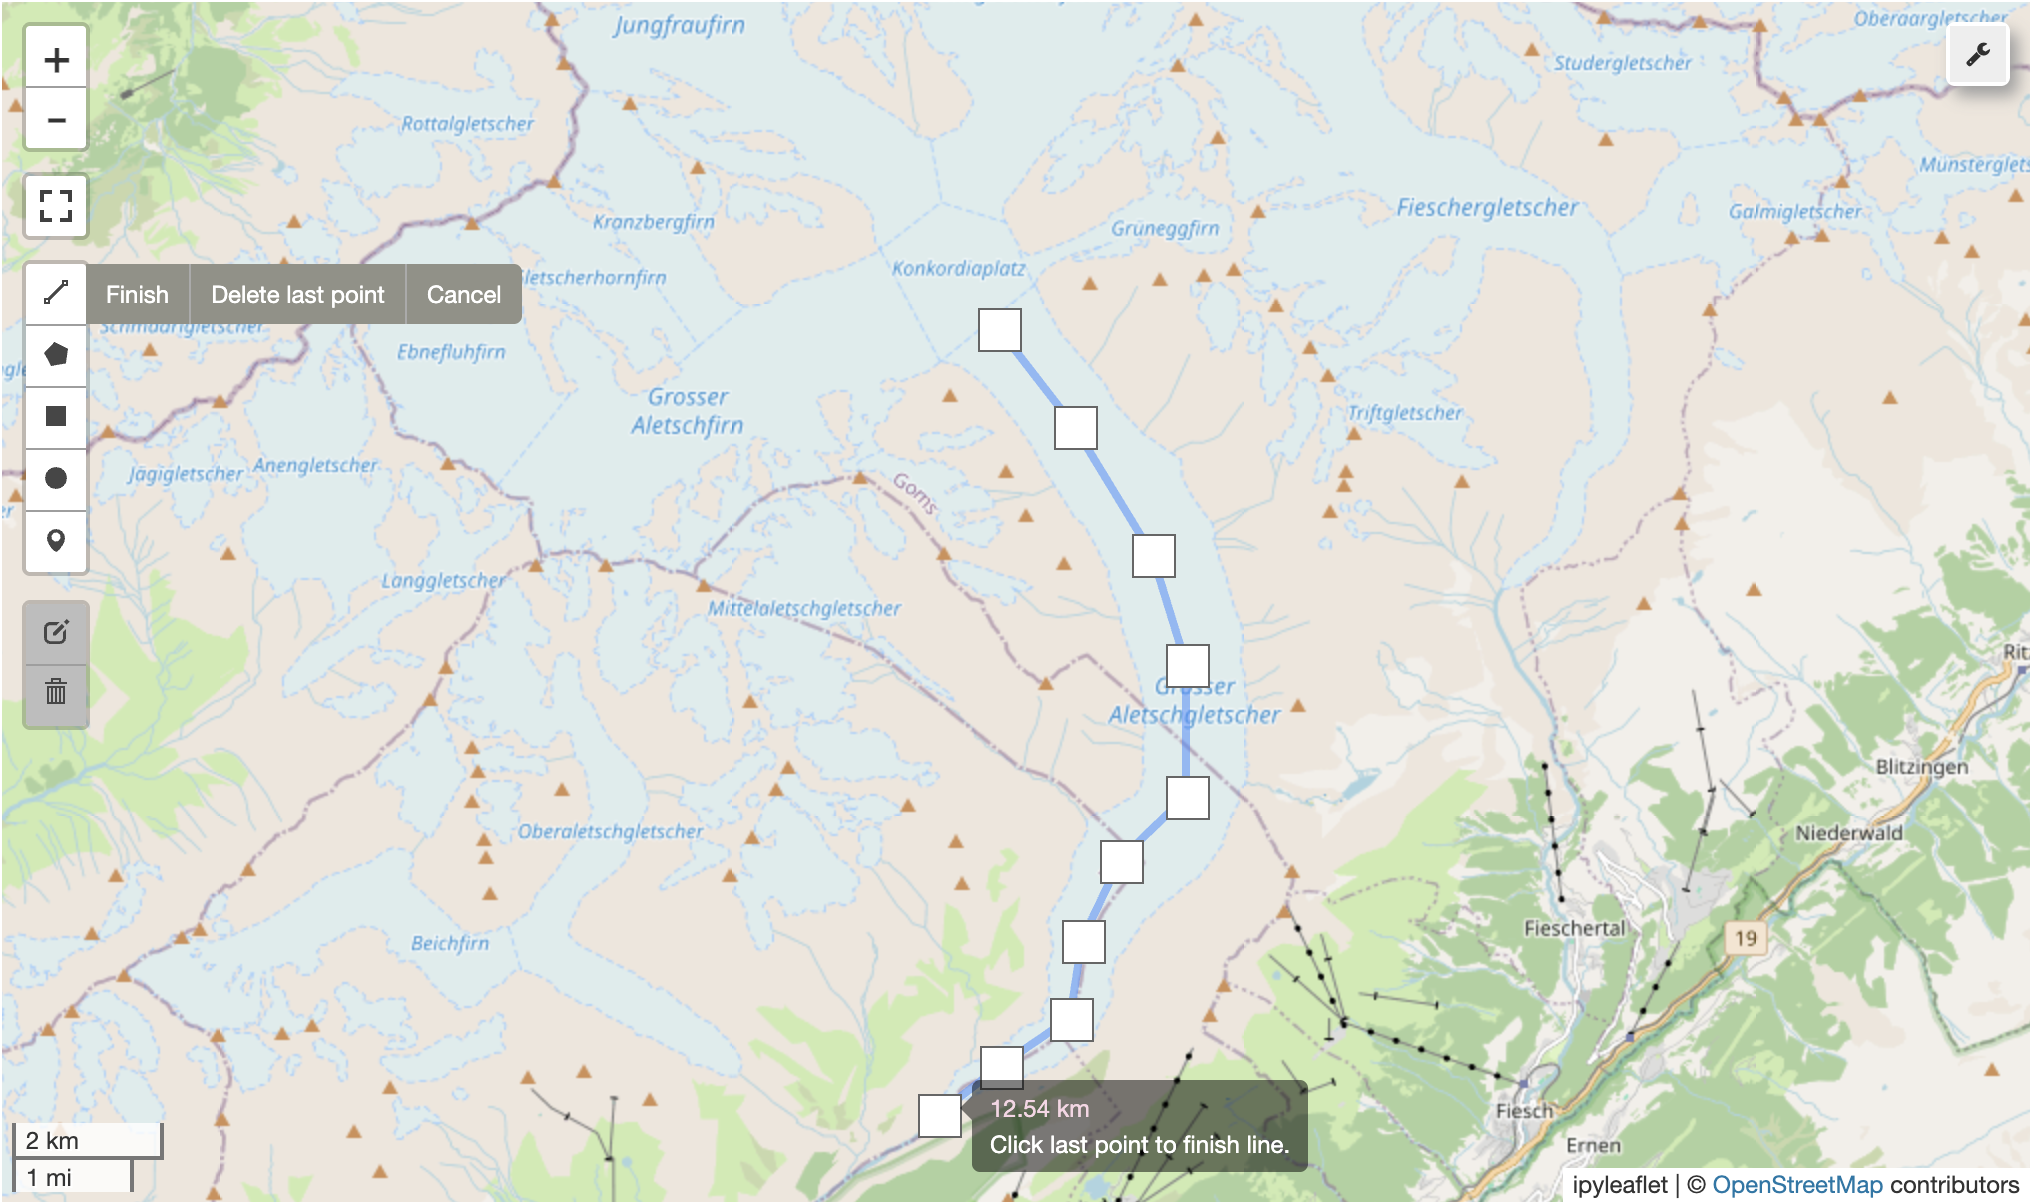
<figcaption aria-hidden="true">Gletscherverlauf</figcaption>
</figure>

Zuerst wird das Tool *Draw a Polyline* verwendet, um den
Gletscherverlauf nachzuzeichnen. Die Pixelwerte entlang dieser Linie
werden später in einem Diagramm dargestellt. Beende das Zeichnen mit
einem Klick auf den **letzten Punkt** und aktiviere die nachfolgenden
Zellen, um das Diagramm zu erzeugen.

In [ ]:
m = leafmap.Map(center=[46.47, 8.04], zoom=12)
m

In [ ]:
# Extrahiert die Koordinaten eurer gezeichnetes Linie
roi_geometry = m.user_roi.get('geometry', {})
roi_coords = roi_geometry.get('coordinates', [])

# Koordinaten für die Analyse übernehmen
custom_route_coords = [(c[0], c[1]) for c in roi_coords]

Nun da ihr den Verlauf nachgezeichnet habt, kann dieser jetzt in einem
Diagramm dargestellt werden. Das macht ihr wieder in 3 Schritten:

**Schritt 1**: Daten aus den Höhenmodellen auslesen

Mit diesem Schritt könnt ihr die Höhenwerte eurer gezeichneten Linie
auslesen.

In [ ]:
def extract_profile(path, coords):
    with rasterio.open(path) as src:
        data = src.read(1)
        transform = ~src.transform
        profile = []

        for p1, p2 in zip(coords[:-1], coords[1:]):
            x1, y1 = transform * p1
            x2, y2 = transform * p2
            x = np.linspace(x1, x2, 50).astype(int)
            y = np.linspace(y1, y2, 50).astype(int)
            profile.extend(data[y, x][:-1])

        profile.append(data[int(y2), int(x2)])
        return np.array(profile)

**Schritt 2**: Höhenprofil erstellen und vergleichen

Mit der Funktion `extract_profile` könnt ihr die beiden Höhenmodelle
auslesen und die Differenz berechnen. Mit `custom_route_coords`könnt ihr
eure gezeichnete Linie auf das jeweilige Höhenmodell übertragen.

In [ ]:
# Höhemodelle auslesen und gezeichnete Linie auslesen
srtm = extract_profile("data/AletschG_SRTMGL1.tif", custom_route_coords)
cop = extract_profile("data/AletschG_Cop30_DEM.tif", custom_route_coords)

# Differenz berechnen
diff = cop - srtm
x = range(len(cop))

**Schritt 3**: Höhenprofile darstellen

Als letzten Schritt könnt ihr eure gezeichnete Linie als Höhenprofile
der beiden Geländemodelle darstellen.

In [ ]:
# Diagramm darstellen
plt.figure(figsize=(14, 7))
plt.subplot(2, 1, 1)
plt.plot(srtm, label="SRTM (2000)", color="blue")
plt.plot(cop, label="Copernicus (Aktuell)", color="red")
plt.fill_between(x, srtm, cop, where=srtm > cop,
                 color="gray", alpha=0.3, label="Eisverlust")
plt.title("Höhenprofil entlang der Route")
plt.ylabel("Höhe (m)")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

Im Diagramm wird der Verlust von Eismasse über die gesamte Länge des
Gletschers deutlich sichtbar.

#### Aufgabe 3

Beschreibt, was das Diagramm zeigt und wie sich die Höhe des Gletschers
verändert hat.

(*10 Minuten*)

Übrigens: Das Deutsche Zentrum für Luft- und Raumfahrt (DLR) hat eine
solche Analyse für die gesamten Alpen durchgeführt:<br>

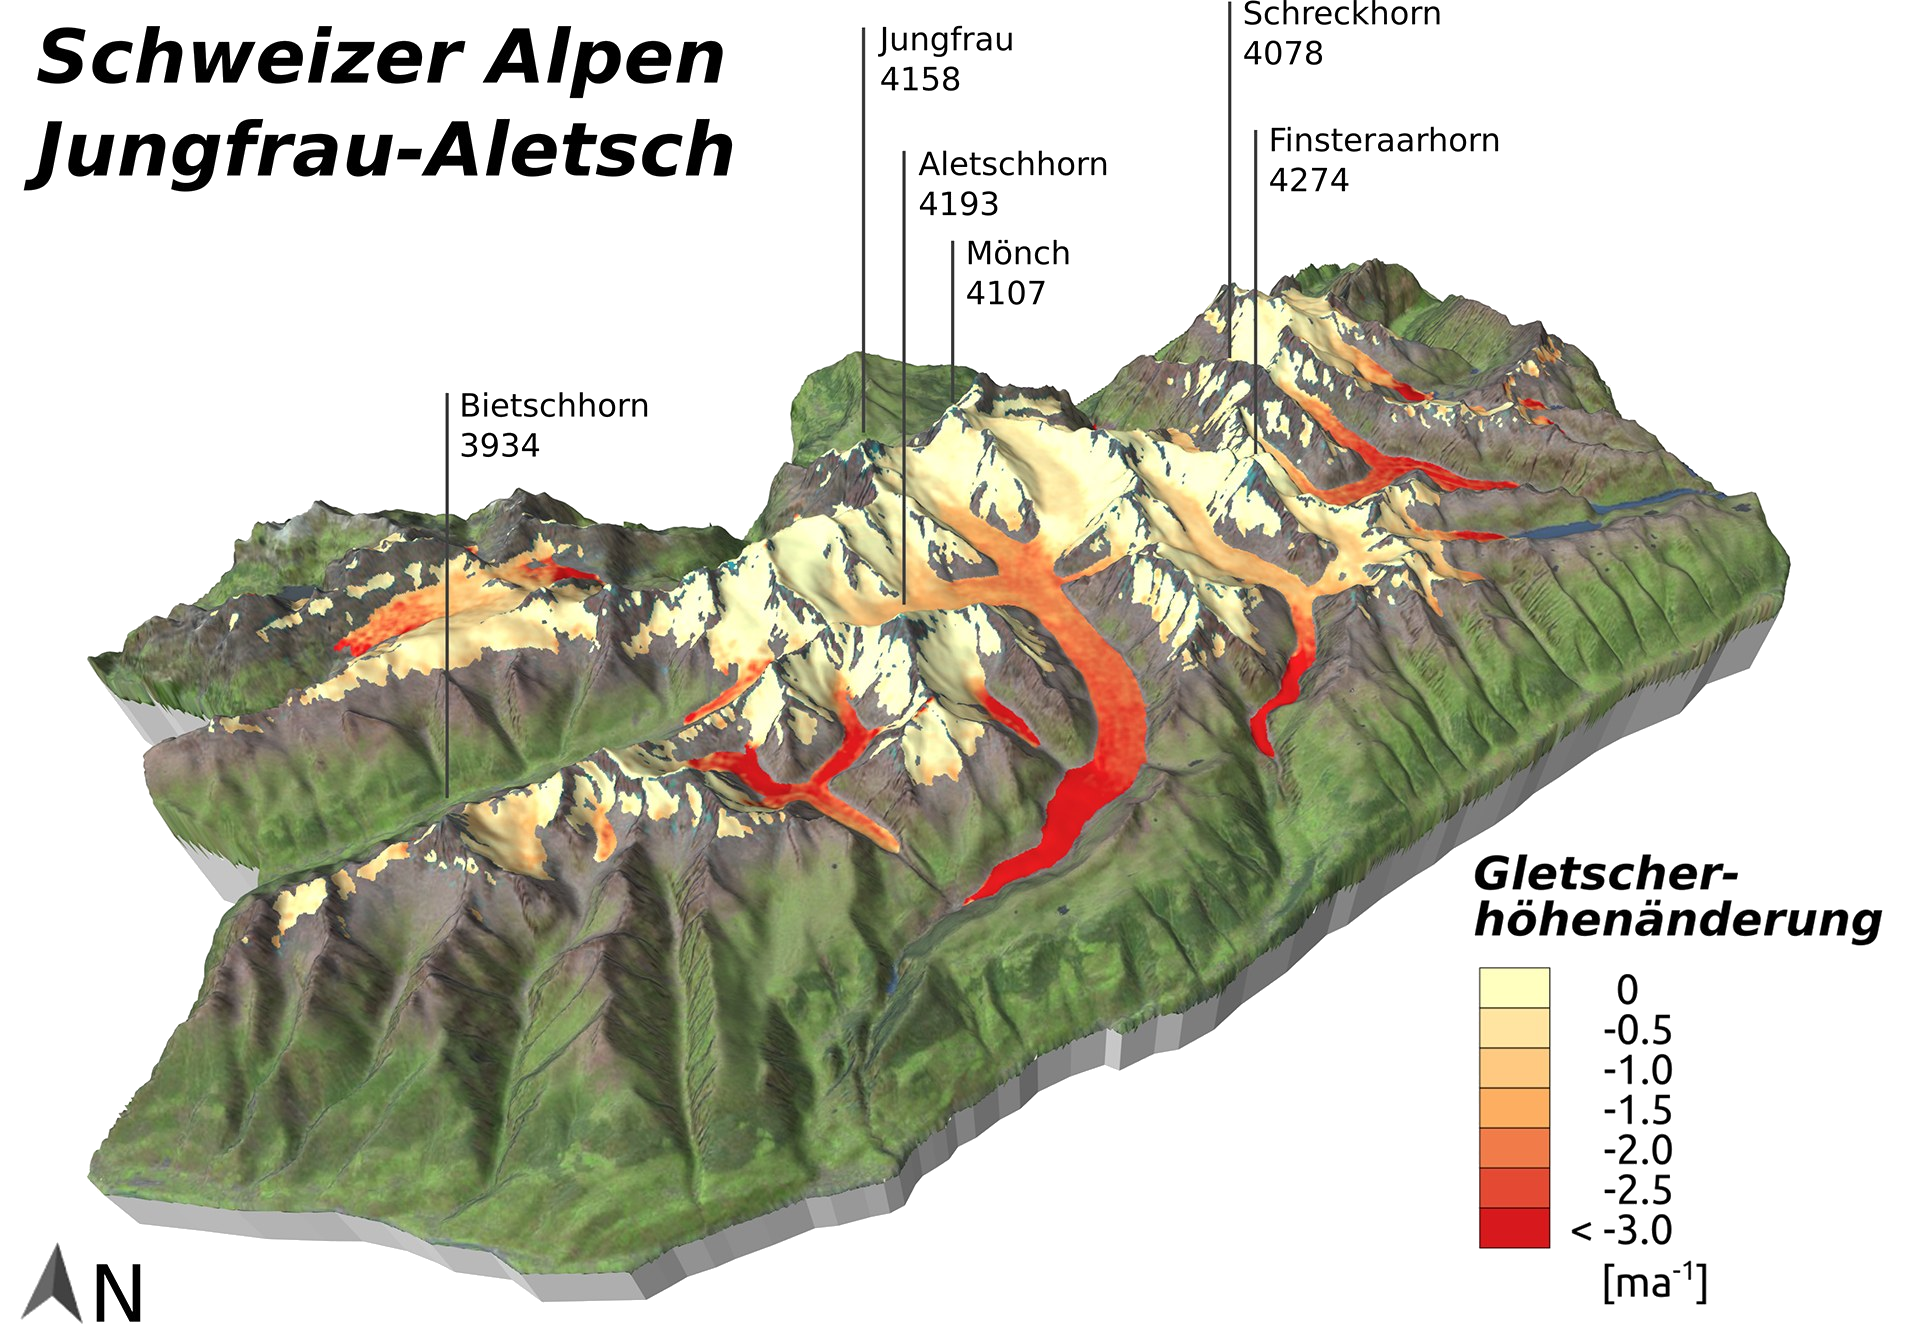
[Bildquelle](https://www.dlr.de/de/aktuelles/nachrichten/2020/03/20200708_gletscherrueckgang-in-den-alpen-erstmals-flaechendeckend-dokumentiert)

# 3. Welttag der Gletscher

Habt ihr gewusst, dass der 21. März erstmals 2025 von den Vereinten
Nationen zum Welttag der Gletscher ausgerufen wurde?

In Deutschland erhalten Flüsse wie Rhein, Donau, Isar und Lech einen
Teil ihres Wassers aus dem Schmelzwasser der Alpen-Gletscher.
Veränderungen der Gletscher beeinflussen nicht nur die Flüsse als
Lebensraum, sondern auch die Schifffahrt sowie Industrien und Kraftwerke
entlang der Flüsse erheblich. Seit 1975 sind 9580 Gt (Gigatonnen) der
weltweiten Gletscher geschmolzen - das kann man sich kaum vorstellen.
<b><a href="https://dgvn.de/meldung/21-maerz-welttag-der-gletscher">Weitere
Informationen hierzu findet ihr bei der deutschen Gesellschaft für die
Vereinten Nationen e.V.</a></b>

# 4. Zusammenfassung

In diesem Modul habt ihr gelernt:

-   was ein Geländemodell ist
-   verschiedene Darstellungen eines Gletschers zu untersuchen
-   mit dem Inspector die Pixelwerte abzulesen
-   den Gletscherrückgang zu untersuchen
-   den Gletscherverlauf mit der Polyline nachzuzeichnen